In [2]:
import concurrent.futures
import time
import glob

from scipy import ndimage
from scipy.optimize import curve_fit

import astropy.units as u
import matplotlib.pyplot as plt
import matplotlib.patches as mp
import numpy as np
import pandas as pd
import pyvo
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
import shutil

In [13]:
import warnings
from matplotlib import rcParams
# Ignore all warnings
warnings.filterwarnings('ignore')
rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'custom',
    'mathtext.rm': 'Times New Roman',
    'mathtext.it': 'Times New Roman:italic',
    'mathtext.bf': 'Times New Roman:bold',
    'font.size': 14
})

## Functions for full ice map:

In [1]:
def cont_fit(w,A,B,C):
    return A*w**2 + B*w + C

def spectrum(ra_points, dec_points, folder, tautype='min', aper=False):
    allfiles = glob.glob(f'{folder}/*.fits')

    wavemap3d = np.zeros((len(ra_points), len(dec_points), len(allfiles)))
    specmap3d = np.zeros((len(ra_points), len(dec_points), len(allfiles)))
    specmap3d[:,:,:] = np.nan
    errmap3d = np.zeros((len(ra_points), len(dec_points), len(allfiles)))
    errmap3d[:,:,:] = np.nan
    
    taumap = np.zeros((len(ra_points), len(dec_points)))
    errmap = np.zeros((len(ra_points), len(dec_points)))
    fwhmmap = np.zeros((len(ra_points), len(dec_points)))
    minmap = np.zeros((len(ra_points), len(dec_points)))
    contmap = np.zeros((len(ra_points), len(dec_points)))
    
    for a in range(len(allfiles)):
        hdulist = fits.open(allfiles[a])
        img = hdulist[1].data
        zodi = hdulist[4].data
        img -= zodi
        #img = ndimage.gaussian_filter(img, 2)
        wave = hdulist[6].data
        err = np.sqrt(hdulist[3].data)
        spectral_image_header = hdulist[1].header
        wcs = WCS(spectral_image_header)
        ra, dec = wcs.wcs.crval
        x, y = wcs.world_to_pixel(SkyCoord(ra=ra, dec=dec, unit="deg"))
        spectral_wcs = WCS(header=hdulist["IMAGE"].header, fobj=hdulist, key="W")
    
        spectral_wcs.sip = None
        wl, bw = spectral_wcs.pixel_to_world(x, y)
        spectral_image = hdulist["IMAGE"]
        spectral_image_data = spectral_image.data
        (y, x) = np.indices(spectral_image.shape)
        spectral_coords = spectral_wcs.pixel_to_world(x, y)
        wavelength, bandwidth = spectral_coords

        img = hdulist[1].data
        arr = img.copy()

        for m in range(len(ra_points)):
            for n in range(len(dec_points)):
                ww, ff, ee = [], [], []
                ra_target = ra_points[m]
                dec_target = dec_points[n]
                coord = SkyCoord(ra=ra_target*u.deg, dec=dec_target*u.deg, frame="icrs") 
                x, y = wcs.world_to_pixel(coord)
                
                try: 
                    p1, p2 = int(x-80), int(x+80)
                    flux = img[int(y+0.5),p1:p2]
                    ferr = err[int(y+0.5),p1:p2]
                    if aper:
                        flux = np.mean(img[int(y+0.5)-2:int(y+0.5)+3, p1:p2], axis=0)
                    lam = wavelength.value[int(y+0.5),int(x+0.5)]
                    #print(y, x, lam)
                    sm = 0.5
                    flux = ndimage.gaussian_filter1d(flux, sm)
                    ferr = ndimage.gaussian_filter1d(ferr, sm) / np.sqrt(2*np.sqrt(np.pi)*sm)
                    if aper: ff.append(np.mean(flux[78:83]))
                    else: 
                        specmap3d[m,n,a] = flux[80]
                        errmap3d[m,n,a] = ferr[80]
                    wavemap3d[m,n,a] = lam
                except: 
                    continue
    #return taumap, errmap, contmap, wavemap3d, specmap3d, errmap3d
    for m in range(len(ra_points)):
        for n in range(len(dec_points)):
            try: 
                ww, ff, ee = np.array(wavemap3d[m,n,:]), np.array(specmap3d[m,n,:]), np.array(errmap3d[m,n,:])
                ww, ff, ee = np.sort(ww), ff[np.argsort(ww)], ee[np.argsort(ww)]
                mask1 = np.where((ww < 2.7) | ((ww >= 3.4) & (ww <= 4.1)))[0]
                contmap[m,n] = np.nanmedian(ff[mask1])
            except: contmap[m,n] = -1
            try:
                ww, ff, ee = np.array(wavemap3d[m,n,:]), np.array(specmap3d[m,n,:]), np.array(errmap3d[m,n,:])
                ww, ff, ee = np.sort(ww), ff[np.argsort(ww)], ee[np.argsort(ww)]
                mask1 = np.where((ww < 2.7) | ((ww >= 3.4) & (ww <= 4.1)))[0]
                ff /= np.nanmedian(ff[mask1])
                mask2 = np.where((ff > 1.5) | (ff < 0.))
                ff[mask2] = np.nan 
                mask3 = np.isnan(ff)
                ww, ff, ee = ww[~mask3], ff[~mask3], ee[~mask3]
    
                mask4 = np.where((ww <= 2.7) | ((ww >= 3.6) & (ww <= 4.1)))[0]
                popt, pcov = curve_fit(cont_fit, ww[mask4], ff[mask4])
                mask5 = np.where((ww >= 2.9) & (ww <= 3.1))[0]

                maskmin = np.nanargmin(ff[mask5])

                if tautype=='min':
                    taumap[m,n] = -np.log(np.nanmedian(ff[mask5][maskmin]) / np.nanmedian(cont_fit(ww[mask5][maskmin], *popt)))
                elif tautype=='avg':
                    taumap[m,n] = -np.log(np.nanmedian(ff[mask5]) / np.nanmedian(cont_fit(ww[mask5], *popt)))
                errmap[m,n] = -np.log(np.nanmedian(ff[mask5]+ee[mask5]) / np.nanmedian(cont_fit(ww[mask5], *popt)))
                errmap[m,n] -= taumap[m,n]
                norm = ff / cont_fit(ww, *popt)
                
                minpoint = np.exp(-taumap[m,n])
                halfpoint = (1 + minpoint) / 2
                crossing_1 = np.where((norm[:-1] > halfpoint) & (norm[1:]<halfpoint))[0][0]
                crossing_2 = np.where((norm[:-1] < halfpoint) & (norm[1:]>halfpoint))[0][0]
                fwhmmap[m,n] = ww[crossing_2] - ww[crossing_1]

                minmap[m,n] = ww[mask5][np.argmin(ff[mask5])]
                #minmap[m,n] = len(mask5)
                #taumap[m,n] = np.sum(cont_fit(ww[mask5], *popt) - ff[mask5])
            except:
                continue
    return taumap, errmap, contmap, wavemap3d, specmap3d, errmap3d

### Please change coordinates below for your core! You can find the central coordinates in my paper. 

### The grid spacing is 0.002 degrees (= 7.2 arcseconds) in Dec. For RA, we use spherical coordinates so the spacing becomes 0.002 / np.cos(declination). Declination inside must be in radians.

### If anything feels off or looks weird or you can't understand, please message me!

In [ ]:
import astropy.units as u

ra_points = np.arange(325.75-0.005*30, 325.75+0.005*30, 0.005)
dec_points = np.arange(66.10833-0.002*30, 66.10833+0.002*30, 0.002)

tau8B, err8B, cont8B, fullwave, fullspec = spectrum(ra_points, dec_points, '../Jenny/NGC-7129-D6', 'avg')

In [ ]:
np.save('fullwave.npy', fullwave)
np.save('fullspec.npy', fullspec)

## Spatial Smoothing and Plotting:

In [4]:
import numpy as np
from scipy.ndimage import gaussian_filter

def nanmedian_filter(arr, size=3):
    """
    Replace NaNs with the median of neighboring values.
    """
    arr = arr.copy()
    nan_mask = np.isnan(arr)

    padded = np.pad(arr, size // 2, mode='reflect')

    for i, j in zip(*np.where(nan_mask)):
        window = padded[i:i+size, j:j+size]
        arr[i, j] = np.nanmedian(window)

    return arr


def gaussian_smooth_nan(arr, sigma=1, median_size=3):
    """
    Fill NaNs using neighbor median, then Gaussian smooth.
    """
    filled = nanmedian_filter(arr, size=median_size)
    smoothed = gaussian_filter(filled, sigma=sigma)
    return smoothed


# Example
a = np.array([
    [1, 2, np.nan, 4],
    [2, np.nan, 3, 5],
    [1, 2, 3, 4]
], dtype=float)

result = gaussian_smooth_nan(a, sigma=1)

print(result)

[[1.63679332 2.24568213 3.17107441 3.85910041]
 [1.69884275 2.24350656 3.14111746 3.88019582]
 [1.61991123 2.17568396 3.05451382 3.77357814]]


### The code below for plotting is not clean or very readable. Might be easier to write your own from scratch!

In [ ]:
tt = tau2.copy()
tt[np.where(tt==0)] = np.nan
tnew = gaussian_smooth_nan(np.array(tt.T),0.5)
plt.imshow(tnew, vmin=0.3, vmax=1.1, cmap=cmocean.cm.ice, origin='lower',
              extent = [-0.002*30*60, 0.002*30*60, -0.002*30*60, 0.002*30*60])
plt.contour(tnew, origin='lower', levels = [0.5, 0.67, 0.83, 1], cmap='Reds', linewidths=0.7,
              extent = [-0.002*30*60, 0.002*30*60, -0.002*30*60, 0.002*30*60], alpha=0.7)
plt.axhline(0, color='white', lw=0.5,alpha=0.4)
plt.axvline(0, color='white', lw=0.5,alpha=0.4)

dra = (tbl["ra"] - coord.ra.deg) * np.cos(coord.dec.radian) * 60
ddec = (tbl["dec"] - coord.dec.deg) * 60
plt.scatter(dra, ddec, c='deeppink', s=1)

plt.gca().invert_xaxis()

tau =  0.23938237550337071
tau =  0.18513342189743356
tau =  0.13321710106882342


/var/folders/73/5cpbpjm96nn4n2mcc500_zbh0000gn/T/ipykernel_6277/4130860114.py:26: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


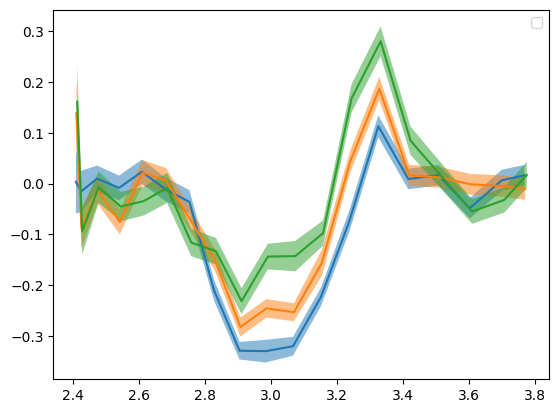

In [1443]:
def cont_fit(w,A,B,C):
    return A*w**2 + B*w + C
#f3[10] = np.nan
#plt.plot(w2, f2/np.nanmedian(f2[:5]), marker='d', label='Closest to centre')
for ww, ff, ee in zip([w1, w2, w3], [f1, f2, f3], [e1, e2, e3]):
    wv, fv, ev = ww.copy(), ff.copy(), ee.copy()
    mask = np.isnan(fv)
    wv, fv, ev = wv[~mask], fv[~mask], ev[~mask]
    mask = np.where((wv <= 2.7) | (wv >= 3.35))[0]
    popt, pcov = curve_fit(cont_fit, wv[mask], fv[mask])
    #plt.plot(wv, cont_fit(wv, *popt)/np.nanmedian(fv[-7:]), color='k', lw=0.7)
    y1 = (fv-cont_fit(wv, *popt))/np.nanmedian(fv[:6])
    y2 = (fv-ev-cont_fit(wv, *popt))/np.nanmedian(fv[:6])
    y3 = (fv+ev-cont_fit(wv, *popt))/np.nanmedian(fv[:6])
    plt.plot(wv, y1, marker='')
    plt.fill_between(wv, y2, y3, alpha=0.5)
    print('tau = ',-np.log10(np.nanmin(fv) / cont_fit(wv[np.nanargmin(fv)],*popt)))

if 0:
    plt.plot(w1, f1/np.nanmedian(f1[-7:]), marker='', label='Centre')
    plt.fill_between(w1, (f1-e1)/np.nanmedian(f1[-7:]), (f1+e1)/np.nanmedian(f1[-7:]), color='C0', alpha=0.5)
    plt.plot(w2, f2/np.nanmedian(f2[-7:]), marker='', label='Farthest')
    plt.fill_between(w2, (f2-e2)/np.nanmedian(f2[-7:]), (f2+e2)/np.nanmedian(f2[-7:]), color='C1', alpha=0.5)
    plt.plot(w3, f3/np.nanmedian(f3[-7:]), marker='', label='Outside')
    plt.fill_between(w3, (f3-e3)/np.nanmedian(f3[-7:]), (f3+e3)/np.nanmedian(f3[-7:]), color='C2', alpha=0.5)
plt.legend()

In [1423]:
f1/e1

array([ 171.99542,  387.19446,  976.62305, 1028.5131 , 1045.5842 ,
       1041.9741 ,  981.05695,  918.1543 ,  993.29346,  464.86633,
        750.05676,  959.9347 ,  912.5521 , 1081.9872 , 1070.8441 ,
       1065.0919 ,  988.73645,  902.15826, 1056.3855 ], dtype=float32)

In [56]:
ra_points = np.arange(67.1620833-0.0023*30, 67.1620833+0.0023*30, 0.0023)
dec_points = np.arange(26.8607222-0.002*30, 26.8607222+0.002*30, 0.002)

tau7, cont7 = spectrum(ra_points, dec_points, 'L1521-SPHEREx')

INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]
INFO: 
             

/var/folders/73/5cpbpjm96nn4n2mcc500_zbh0000gn/T/ipykernel_40466/813953219.py:83: RuntimeWarning: invalid value encountered in log
  taumap[m,n] = -np.log(np.nanmedian(ff[mask5]) / np.nanmedian(cont_fit(ww[mask5], *popt)))


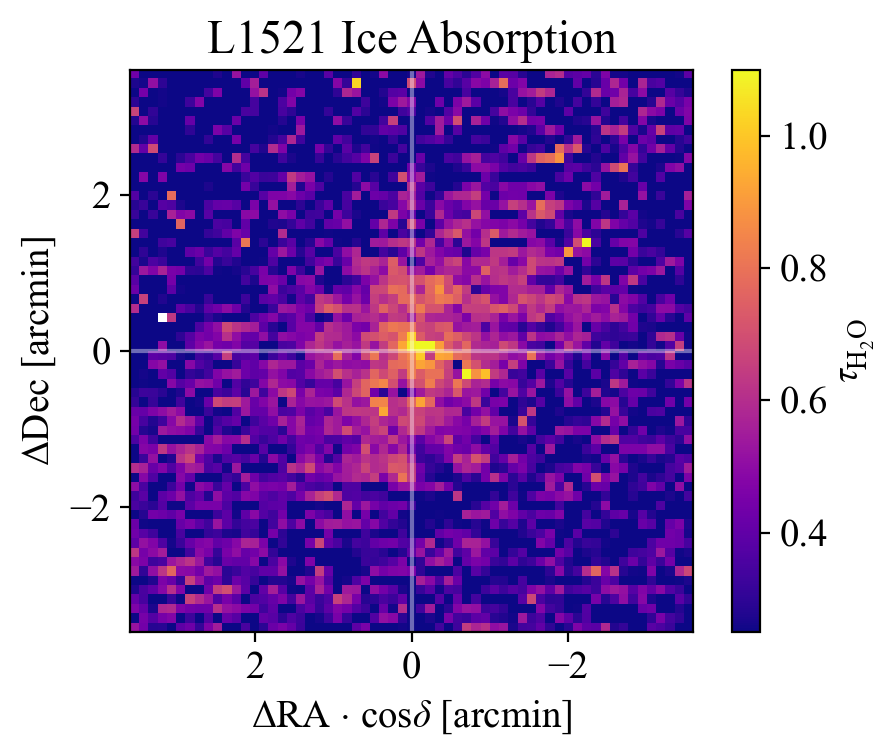

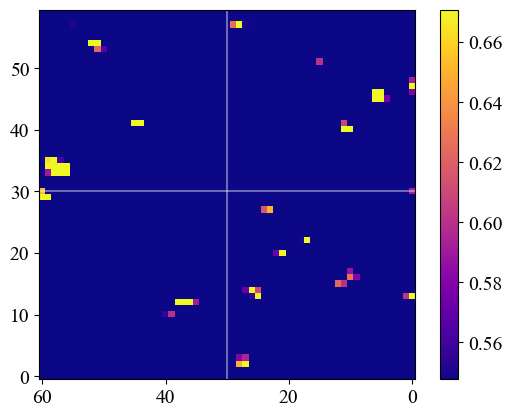

In [103]:
tt = tau7.copy()
tt[np.where(tt==0)] = np.nan

plt.figure(figsize=(5,4), dpi=200)
plt.imshow(np.array(tt.T), vmin=0.25, vmax=1.1, cmap='plasma', origin='lower',
          extent = [-0.002*30*60, 0.002*30*60, -0.002*30*60, 0.002*30*60])
plt.colorbar(label=r'$\tau_{\mathrm{H_2O}}$')
plt.axhline(0, color='white', alpha=0.4)
plt.axvline(0, color='white', alpha=0.4)
plt.xlabel(r'$\Delta$RA $\cdot$ cos$\delta$ [arcmin]')
plt.ylabel(r'$\Delta$Dec [arcmin]')
plt.gca().invert_xaxis()
plt.title('L1521 Ice Absorption')
rlist = [67.1620833, 67.1660833, 67.1730833, ]
dlist = [26.8607222, 26.8547222, 26.8457222, ]
ra0, dec0 = rlist[0], dlist[0]
for rr, dd in zip(rlist, dlist):
    rr1 = (rr-ra0) * 60 * np.cos(dd*np.pi/180)
    dd1 = (dd-dec0) * 60
    #plt.scatter(rr1, dd1, marker='x', color='limegreen', alpha=0.5)
plt.tight_layout()
plt.savefig('Paper1.2/L1521-icemap.pdf', bbox_inches='tight', pad_inches=0)
plt.show()

gn = 1/2
plt.imshow(np.array(cont7.T)**gn, vmin=0.3**gn, vmax=0.45**gn, cmap='plasma', origin='lower')
plt.colorbar()
plt.axhline(30, color='white', alpha=0.4)
plt.axvline(30, color='white', alpha=0.4)
plt.gca().invert_xaxis()
plt.show()

In [1454]:
rlist = [67.1620833, 67.1660833, 67.1560833, ]
dlist = [26.8607222, 26.8547222, 26.8647222, ]

w1, f1, e1 = spectrum(rlist[0], dlist[0], 'L1521-SPHEREx')
w2, f2, e2 = spectrum(rlist[1], dlist[1], 'L1521-SPHEREx')
w3, f3, e3 = spectrum(rlist[2], dlist[2], 'L1521-SPHEREx')

INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]
1294.7144263262578 1

tau =  0.16721459037084246
tau =  0.05811441888089898
tau =  0.07108667074760291


/var/folders/73/5cpbpjm96nn4n2mcc500_zbh0000gn/T/ipykernel_6277/3913209546.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


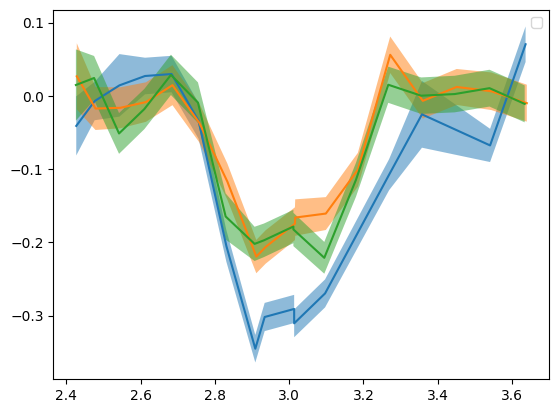

In [1456]:
def cont_fit(w,A,B,C):
    return A*w**2 + B*w + C
f1[-3] = f1[-6] = np.nan
#f3[5] = np.nan
#plt.plot(w2, f2/np.nanmedian(f2[:5]), marker='d', label='Closest to centre')
for ww, ff, ee in zip([w1, w2, w3], [f1, f2, f3], [e1, e2, e3]):
    wv, fv, ev = ww.copy(), ff.copy(), ee.copy()
    mask = np.isnan(fv)
    wv, fv, ev = wv[~mask], fv[~mask], ev[~mask]
    mask = np.where((wv <= 2.7) | (wv >= 3.35))[0]
    popt, pcov = curve_fit(cont_fit, wv[mask], fv[mask])
    #plt.plot(wv, cont_fit(wv, *popt)/np.nanmedian(fv[-7:]), color='k', lw=0.7)
    y1 = (fv-cont_fit(wv, *popt))/np.nanmedian(fv[:6])
    y2 = (fv-ev-cont_fit(wv, *popt))/np.nanmedian(fv[:6])
    y3 = (fv+ev-cont_fit(wv, *popt))/np.nanmedian(fv[:6])
    plt.plot(wv, y1, marker='')
    plt.fill_between(wv, y2, y3, alpha=0.5)
    mask = np.where(((wv <= 2.95) | (wv >= 3.05)) & ~np.isnan(fv))[0]
    tau_all = -np.log(fv[~mask] / cont_fit(wv[~mask],*popt))
    #plt.plot(wv, (fv-cont_fit(wv, *popt))/np.nanmedian(fv[:5]), marker='d')
    print('tau = ',np.nanmean(tau_all))

if 0:
    plt.plot(w1, f1/np.nanmedian(f1[:6]), marker='d', label='Centre')
    plt.plot(w2, f2/np.nanmedian(f2[:6]), marker='d', label='Farthest')
    plt.plot(w3, f3/np.nanmedian(f3[:6]), marker='d', label='Outside')
plt.legend()

In [401]:
ra_points = np.arange(166.6906667-0.008*30, 166.6906667+0.008*30, 0.008)
dec_points = np.arange(-77.3758333-0.002*30, -77.3758333+0.002*30, 0.002)

tau7, err7, cont7, fwhm7, min7 = spectrum(ra_points, dec_points, 'Ced110-SPHEREx')

INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]
INFO: 
             

In [60]:
cont7

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


NameError: name 'cont7' is not defined

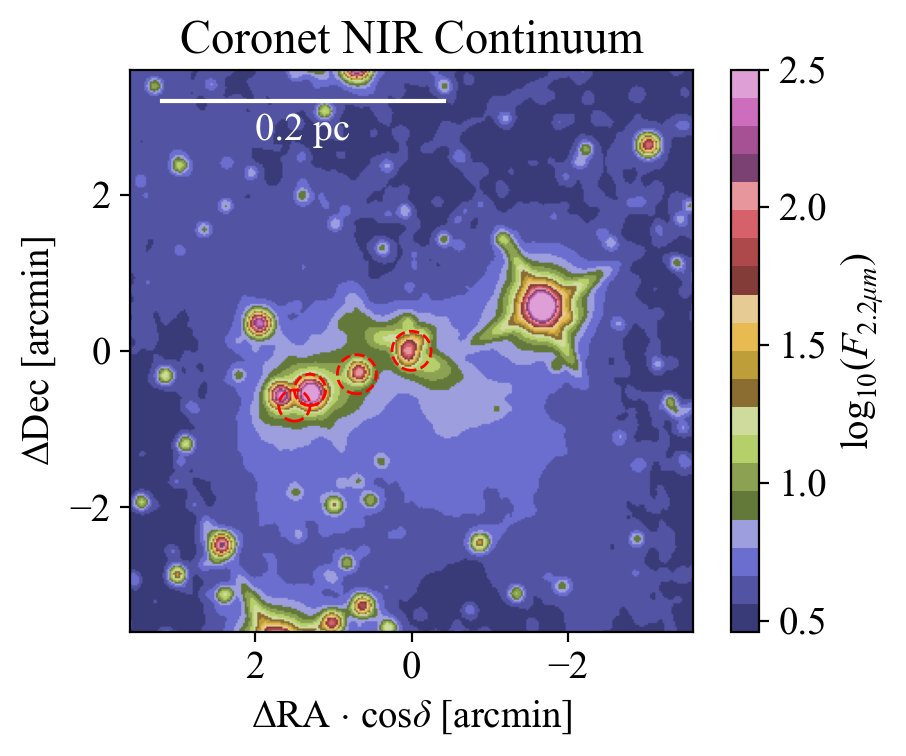

In [676]:
ff = fits.open('WISE_Images/Ced110_0.fits')

rlist = [166.6906667, 166.7056667, 166.7206667]   
dlist = [-77.3758333, -77.3728333, -77.3710333]
ra0, dec0 = rlist[0]-0.00, dlist[0]-0.00

hh = ff[0].header
fluxdata = dd = np.log10(ff[0].data)
cra, cdec = hh['CRVAL1'], hh['CRVAL2']
cp1, cp2 = hh['CRPIX1'], hh['CRPIX2']
dra, ddec = hh['CDELT1'], hh['CDELT2']
#ra0, dec0 = cra, cdec
cosd = np.cos(dec0*np.pi/180)

p1, p2 = int((ra0-0.06/cosd-cra)*cosd / dra + cp1), int((ra0+0.06/cosd-cra)*cosd / dra + cp1)
p3, p4 = int((dec0-0.06-cdec) / ddec + cp2), int((dec0+0.06-cdec) / ddec + cp2)

smoothflux4 = dd[p3:p4, p2:p1]

plt.figure(figsize=(5,4), dpi=200)
plt.imshow(smoothflux4, origin='lower', vmax=2.5, cmap='tab20b', extent=[3.6,-3.6,-3.6,3.6])
plt.colorbar(label=r'log$_{10} (F_{2.2 \mu m})$')
#plt.contour(smoothflux4, origin='lower', levels=[0,0.62,0.8,2,2.5], linewdiths=0.6, cmap='Reds', extent=[3.6,-3.6,-3.6,3.6])

plt.gca().add_patch(plt.Circle((1.3,-0.5),0.2,fill=False,color='r', ls='--'))
plt.gca().add_patch(plt.Circle((1.5,-0.7),0.2,fill=False,color='r', ls='--'))
plt.gca().add_patch(plt.Circle((0.7,-0.3),0.25,fill=False,color='r', ls='--'))
plt.gca().add_patch(plt.Circle((0,0),0.25,fill=False,color='r', ls='--'))
plt.title('Coronet NIR Continuum')


dist = 190
plt.plot([3.2, 3.2-0.2/dist*180/np.pi*60], [3.2,3.2], color='white')
plt.text(2.,2.7,'0.2 pc', color='white')

plt.xlabel(r'$\Delta$RA $\cdot$ cos$\delta$ [arcmin]')
plt.ylabel(r'$\Delta$Dec [arcmin]')
plt.tight_layout()
#plt.savefig('Paper2.1/Ced110-fluxmap.pdf', bbox_inches='tight', pad_inches=0)

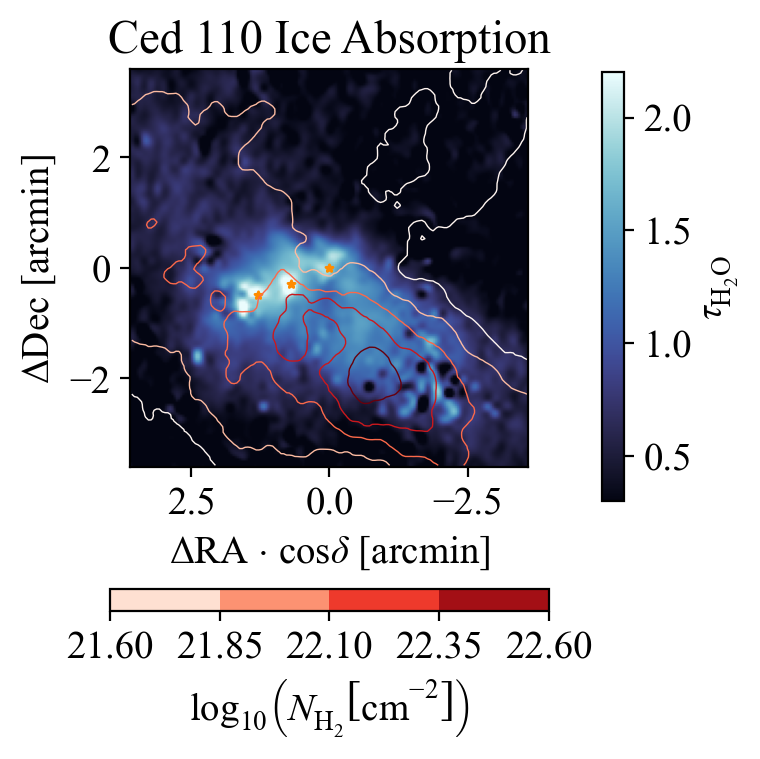

NameError: name 'cont8' is not defined

In [58]:
tnew = gaussian_smooth_nan(fits.open('IceMaps/Ced110_tau_maps.fits')[1].data[:,:],0.2)
#tnew = tt.T
cmap = cmocean.cm.ice.copy() 
cmap.set_bad(color='yellow')

plt.figure(figsize=(5,4), dpi=200)
plt.imshow(zoom(tnew, zoom=3, order=3), vmin=0.3, vmax=2.2, cmap=cmap, origin='lower', zorder=1,
          extent = [-0.002*30*60, 0.002*30*60, -0.002*30*60, 0.002*30*60])
plt.colorbar(location='right', shrink=0.7,
             label=r'$\tau_{\mathrm{H_2O}}$', anchor=(-1.2,0.98))

#smoothflux = np.log10(cont9.T)[:,-1:1:-1]
#smoothflux2 = gaussian_smooth_nan(fluxdata[p3:p4, p2:p1],3).copy()
h2map = gaussian_smooth_nan(np.load('WISE_Images/Ced 110_H2.npy'),0.02)
levels = [21.48,21.7,21.9,21.95,22.01,22.13,22.18,22.27,22.48,22.6,22.8,23]
levels = np.arange(21.6,22.7,0.25)
plt.contour(h2map, origin='lower', levels=levels, cmap='Reds', linewidths=1/2, extent=[3.6,-3.6,-3.6,3.6])
plt.contourf(h2map, origin='lower', levels=levels, cmap='Reds', linewidths=1/2, extent=[3.6,-3.6,-3.6,3.6], zorder=0)
plt.colorbar(location='bottom', shrink=0.6, pad=0.2,
             label=r'log$_{10}\left(N_{\rm H_2} \left[{\rm cm}^{-2}\right]\right)$')

plt.xlabel(r'$\Delta$RA $\cdot$ cos$\delta$ [arcmin]')
plt.ylabel(r'$\Delta$Dec [arcmin]')
plt.gca().invert_xaxis()
plt.title('Ced 110 Ice Absorption')
rlist = [76.0697917, 76.0567917, 76.0437917]
dlist = [25.18125, 25.19025, 25.20625]
rlist = [166.6375000, 166.6375000, 166.6375000, 166.56797, 166.60577, 166.58162, 166.59044]   
dlist = [-77.3930556, -77.4030556, -77.4130556, -77.40469, -77.38768, -77.40297, -77.39820]
ra0, dec0 = 166.6906667, -77.3758333
for rr, dd in zip(rlist, dlist):
    rr1 = (rr-ra0) * 60 * np.cos(dd*np.pi/180)
    dd1 = (dd-dec0) * 60
    #plt.scatter(rr1, dd1, marker='x', color='limegreen', alpha=0.5)

plt.scatter([1.3,0.7,0],[-0.5,-0.3,0],marker='*',s=7,color='darkorange')
if 0:
    plt.gca().add_patch(plt.Circle((1.3,-0.5),0.2,fill=False,color='r', ls='--'))
    plt.gca().add_patch(plt.Circle((0.7,-0.3),0.25,fill=False,color='r', ls='--'))
    plt.gca().add_patch(plt.Circle((0,0),0.25,fill=False,color='r', ls='--'))
    
plt.tight_layout()
plt.savefig('Paper2.1/Ced110-icemap.pdf', bbox_inches='tight', pad_inches=0)
plt.show()



gn = 1/3
plt.imshow(np.array(cont8.T)**gn, vmin=0.3**gn, vmax=1.45**gn, cmap='plasma', origin='lower')
plt.colorbar()
plt.axhline(30, color='white', alpha=0.4)
plt.axvline(30, color='white', alpha=0.4)
plt.gca().invert_xaxis()
plt.show()

In [116]:
rlist = [166.6906667, 166.7056667, 166.7206667, 166.7406667]   
dlist = [-77.3758333, -77.3728333, -77.3710333, -77.3643333]

#rlist = [166.7956667, 166.7956667, 166.7956667]   
#dlist = [-77.3960333, -77.3950333, -77.3900333]

w1, f1, e1 = spectrum(rlist[0], dlist[0], 'Ced110-SPHEREx')
#w2, f2, e2 = spectrum(rlist[1], dlist[1], 'Ced110-SPHEREx')
#w3, f3, e3 = spectrum(rlist[2], dlist[2], 'Ced110-SPHEREx')
#w4, f4, e4 = spectrum(rlist[3], dlist[3], 'Ced110-SPHEREx')

INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]
1415.1187810994197 7

tau =  0.21399415107147474
tau =  0.1810299161296962
tau =  0.15777676800715784
tau =  0.00798549967245554


/var/folders/73/5cpbpjm96nn4n2mcc500_zbh0000gn/T/ipykernel_29016/3558234800.py:31: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


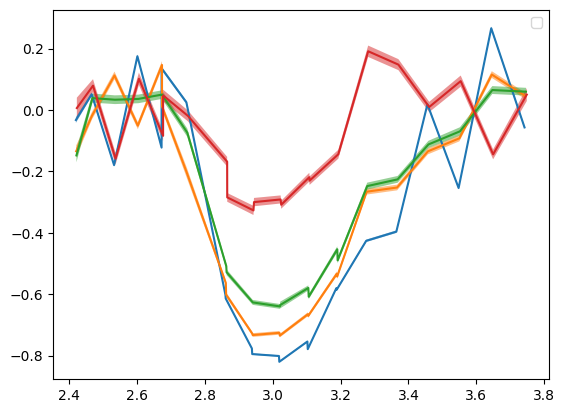

In [118]:
def cont_fit(w,A,B,C):
    return A*w**2 + B*w + C
#f1[0] = f2[0] = f3[0] = np.nan
#f4[10] = np.nan
#f3[5] = np.nan
#f2[10] = np.nan
#plt.plot(w2, f2/np.nanmedian(f2[:5]), marker='d', label='Closest to centre')
for ww, ff, ee in zip([w1, w2, w3, w4], [f1, f2, f3, f4], [e1, e2, e3, e4]):
    #continue
    wv, fv, ev = ww.copy(), ff.copy(), ee.copy()
    mask = np.isnan(fv)
    wv, fv, ev = wv[~mask], fv[~mask], ev[~mask]
    mask = np.where((wv <= 2.7) | (wv >= 3.4))[0]
    popt, pcov = curve_fit(cont_fit, wv[mask], fv[mask])
    #plt.plot(wv, cont_fit(wv, *popt)/np.nanmedian(fv[-7:]), color='k', lw=0.7)
    y1 = (fv-cont_fit(wv, *popt))/np.nanmedian(fv[:6])
    y2 = (fv-ev-cont_fit(wv, *popt))/np.nanmedian(fv[:6])
    y3 = (fv+ev-cont_fit(wv, *popt))/np.nanmedian(fv[:6])
    plt.plot(wv, y1, marker='')
    plt.fill_between(wv, y2, y3, alpha=0.5)
    mask = np.where(((wv <= 2.85) | (wv >= 3.15)) & ~np.isnan(fv))[0]
    tau_all = -np.log(fv[~mask] / cont_fit(wv[~mask],*popt))
    #plt.plot(wv, (fv-cont_fit(wv, *popt))/np.nanmedian(fv[:5]), marker='d')
    print('tau = ',np.nanmean(tau_all))

if 0:
    plt.plot(w1, f1/np.nanmedian(f1[:6]), marker='d', label='Centre')
    plt.plot(w2, f2/np.nanmedian(f2[:6]), marker='d', label='Middle')
    plt.plot(w3, f3/np.nanmedian(f3[:6]), marker='d', label='Outer')
    plt.plot(w4, f4/np.nanmedian(f4[:6]), marker='d', label='Outside')
plt.legend()

INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]


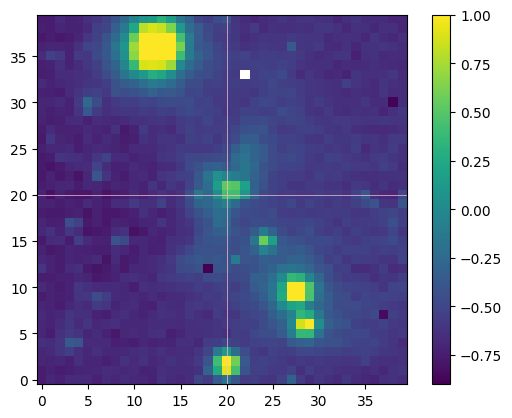

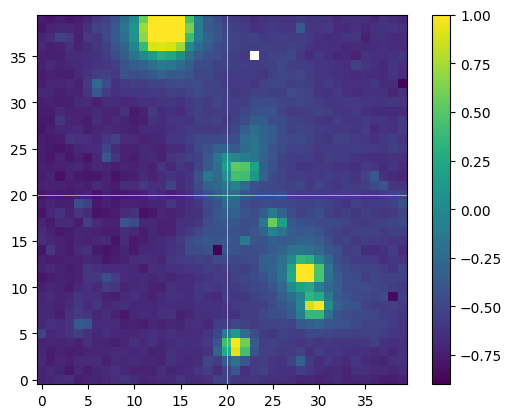

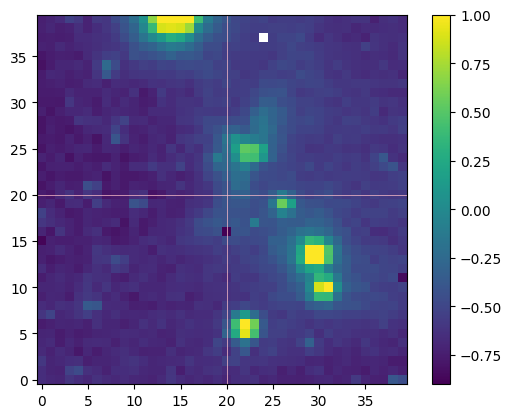

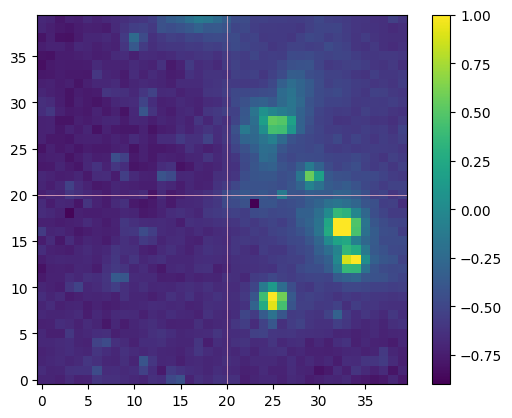

In [115]:
allfiles = glob.glob('L1521-SPHEREx/*.fits')
allfiles = glob.glob('Ced110-SPHEREx/*.fits')
#allfiles = glob.glob('CrA-151-SPHEREx/*.fits')

ww, ff = [], []

for a in allfiles[10:11]:
    hdulist = fits.open(a)
    img = hdulist[1].data
    wave = hdulist[6].data
    spectral_image_header = hdulist[1].header
    wcs = WCS(spectral_image_header)
    ra, dec = wcs.wcs.crval
    x, y = wcs.world_to_pixel(SkyCoord(ra=ra, dec=dec, unit="deg"))
    spectral_wcs = WCS(header=hdulist["IMAGE"].header, fobj=hdulist, key="W")

    spectral_wcs.sip = None
    wl, bw = spectral_wcs.pixel_to_world(x, y)
    spectral_image = hdulist["IMAGE"]
    spectral_image_data = spectral_image.data
    (y, x) = np.indices(spectral_image.shape)
    spectral_coords = spectral_wcs.pixel_to_world(x, y)
    wavelength, bandwidth = spectral_coords

    coord = SkyCoord(ra=287.5840417*u.deg, dec=-37.1408333*u.deg, frame="icrs")
    #coord = SkyCoord(ra=294.2559167*u.deg, dec=7.5698889*u.deg, frame="icrs")
    #coord = SkyCoord(ra=53.3245*u.deg, dec=31.1589*u.deg, frame="icrs")
    #285.4852500 -36.9582500
    rlist = [67.1620833, 67.1680833, 67.1570833]
    dlist = [26.8664222, 26.8707222, 26.8587222]
    rlist = [67.1620833, 67.1660833, 67.1560833, 67.1720833]
    dlist = [26.8664222, 26.8547222, 26.8567222, 26.8767222]
    rlist = [285.4102500, 285.4602500, 285.4502500, 285.4302500]
    dlist = [-36.9602500, -36.9362500, -36.9362500, -36.9362500]
    rlist = [76.0697917, 76.0857917, 76.0997917]
    dlist = [25.18125, 25.17025, 25.14225]
    rlist = [76.0324167, 76.0434167, 76.0544167]   
    dlist = [32.7311667, 32.7301667, 32.7281667]
    rlist = [76.0697917, 76.0857917, 76.0997917]
    dlist = [25.18125, 25.17025, 25.14225]
    rlist = [166.6906667, 166.7056667, 166.7206667, 166.7406667]   
    dlist = [-77.3758333, -77.3728333, -77.3710333, -77.3643333]
    for rr,dd in zip(rlist,dlist):
        coord = SkyCoord(ra=rr*u.deg, dec=dd*u.deg, frame="icrs")
        #294.2529167    7.5688889
        x, y = wcs.world_to_pixel(coord)
        
        img = hdulist[1].data
        arr = img.copy()
    
        p1, p2 = int(x-80), int(x+80)
        flux = img[int(y+0.5),p1:p2]
        lam = wavelength.value[int(y+0.5),p1:p2]
        sm = 2
        flux = ndimage.gaussian_filter1d(flux, sm)
        ww.append(np.mean(lam))
        ff.append(flux)
    
        x1, x2 = int(x-20), int(x+20)
        y1, y2 = int(y-20), int(y+20)
        arr = img.copy()[y1:y2, x1:x2]
        plt.imshow(np.log10(arr), vmin=-0.9, vmax=1, origin='lower')
        #plt.imshow(np.array(arr), vmin=0., vmax=0.55, origin='lower')
        plt.colorbar()
        
        plt.axvline(20, color='pink', lw=0.5)
        plt.axhline(20, color='pink', lw=0.5)
        plt.show()

INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]


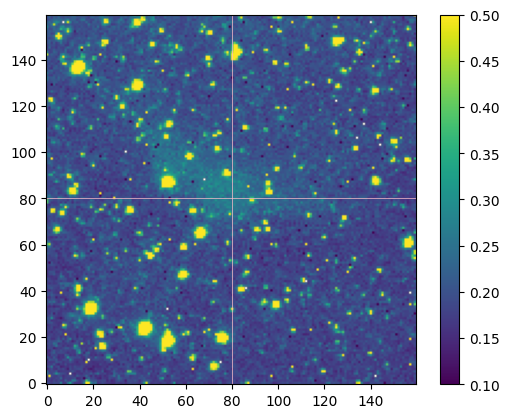

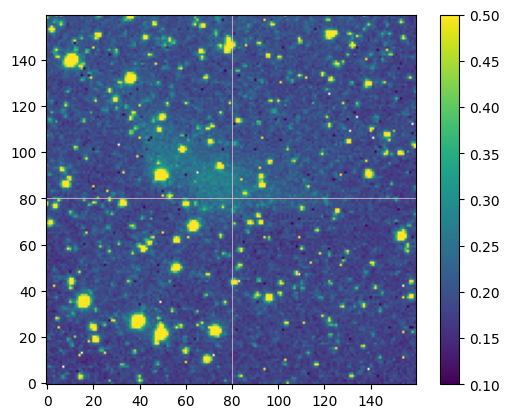

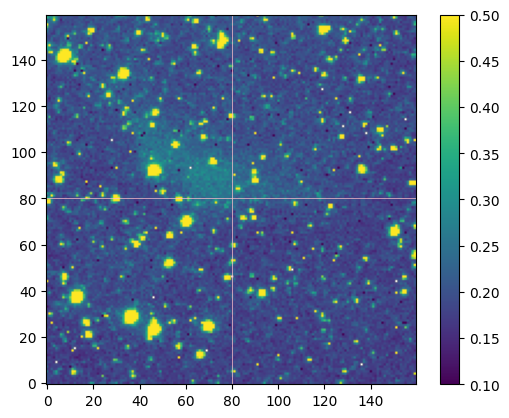

In [1008]:
allfiles = glob.glob('LDN260-SPHEREx/*.fits')
#allfiles = glob.glob('RCrA-SPHEREx/*.fits')
#allfiles = glob.glob('CrA-151-SPHEREx/*.fits')

ww, ff = [], []

for a in allfiles[5:6]:
    hdulist = fits.open(a)
    img = hdulist[1].data
    wave = hdulist[6].data
    spectral_image_header = hdulist[1].header
    wcs = WCS(spectral_image_header)
    ra, dec = wcs.wcs.crval
    x, y = wcs.world_to_pixel(SkyCoord(ra=ra, dec=dec, unit="deg"))
    spectral_wcs = WCS(header=hdulist["IMAGE"].header, fobj=hdulist, key="W")

    spectral_wcs.sip = None
    wl, bw = spectral_wcs.pixel_to_world(x, y)
    spectral_image = hdulist["IMAGE"]
    spectral_image_data = spectral_image.data
    (y, x) = np.indices(spectral_image.shape)
    spectral_coords = spectral_wcs.pixel_to_world(x, y)
    wavelength, bandwidth = spectral_coords

    coord = SkyCoord(ra=287.5840417*u.deg, dec=-37.1408333*u.deg, frame="icrs")
    #coord = SkyCoord(ra=294.2559167*u.deg, dec=7.5698889*u.deg, frame="icrs")
    #coord = SkyCoord(ra=53.3245*u.deg, dec=31.1589*u.deg, frame="icrs")
    #285.4852500 -36.9582500
    rlist = [238.5408333,238.5458333,238.5478333]   
    dlist = [-2.8263333,-2.8103333,-2.803333]
    rlist = [238.5408333,238.5328333,238.5198333]   
    dlist = [-2.8263333,-2.8263333,-2.8233333]
    rlist = [76.0617917, 76.0537917, 76.0237917]
    dlist = [25.18725, 25.20725, 25.23525]
    rlist = [251.7925000, 251.799, 251.805]   
    dlist = [-9.5835556, -9.578, -9.575]
    for rr,dd in zip(rlist,dlist):
        coord = SkyCoord(ra=rr*u.deg, dec=dd*u.deg, frame="icrs")
        #294.2529167    7.5688889
        x, y = wcs.world_to_pixel(coord)
        
        img = hdulist[1].data
        arr = img.copy()
    
        p1, p2 = int(x-80), int(x+80)
        flux = img[int(y+0.5),p1:p2]
        lam = wavelength.value[int(y+0.5),p1:p2]
        sm = 2
        flux = ndimage.gaussian_filter1d(flux, sm)
        ww.append(np.mean(lam))
        ff.append(flux)
    
        x1, x2 = int(x-80), int(x+80)
        y1, y2 = int(y-80), int(y+80)
        arr = img.copy()[y1:y2, x1:x2]
        #plt.imshow(np.log10(arr), vmin=-0.7, vmax=-0.3, origin='lower')
        plt.imshow(np.array(arr), vmin=0.1, vmax=0.5, origin='lower')
        plt.colorbar()
        
        plt.axvline(80, color='pink', lw=0.5)
        plt.axhline(80, color='pink', lw=0.5)
        plt.show()

In [769]:
rlist, dlist

([76.0617917, 76.0477917, 76.0337917],
 [25.18725, 25.201249999999998, 25.215249999999997])

In [427]:
ff = np.array(ff)
ff = ff[np.argsort(ww),:]
ww = np.sort(ww)

s1, s2 =30,31
ff[10,:] = (ff[9,:]+ff[11,:]) / 2
#ff[10,:] = np.nan
s=1

c1, c2, c3 = 71,81,90
for ind, lbl in zip([c1, c2, c3], ['left edge', 'centre', 'right edge']):
    frac = (ind-s1) / (s2-s1)
    r, g, b = frac, 0, 1-frac
    #plt.plot(ww, ff[:,ind]/np.nanmedian(ff[7:13,ind]), label=lbl, marker='d')
    plt.plot(ww, ff[:,ind]/np.nanmedian(ff[:4,ind]), label=lbl, marker='d')
#plt.axvline(ww[10], color='k')
plt.xlabel('Wavelength um')
plt.ylabel('Normalised flux')
#plt.ylim(0,2)
plt.legend()
plt.show()


x1, x2 = int(x-80), int(x+80)
y1, y2 = int(y-80), int(y+80)
arr = img.copy()[y1:y2, x1:x2]
plt.imshow(arr, vmin=0, vmax=1., origin='upper')
plt.colorbar()

[plt.axvline(a, color='pink') for a in [c1, c2, c3]]
plt.axhline(80, color='pink')
plt.show()

IndexError: index 9 is out of bounds for axis 0 with size 4

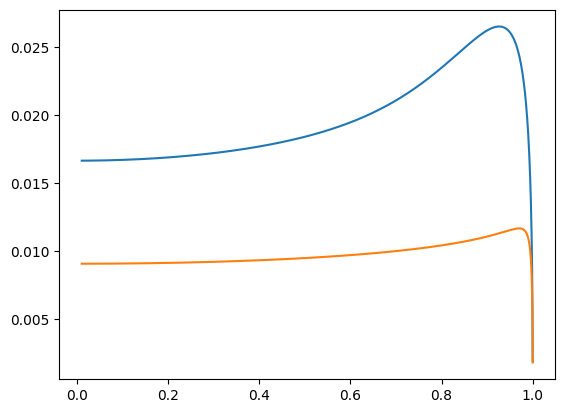

In [721]:
from scipy.integrate import quad

def pathlength_los(u, R, x, R0):
    r = R*np.cos(x)/np.cos(u)
    rho_R = R0**2 / (r**2 + R0**2)
    dl = r / np.cos(u)
    r_evap = R0 * 1
    width = R0 * 0.1
    #ice_abs = 0.75 + 0.25*np.tanh((r - r_evap) / width)
    return rho_R * dl

def pathlength_central(u, R0):
    rho_R = R0**2 / (u**2 + R0**2)
    return rho_R

g = 0.0

def f(t, x, R, R0, tau_h2o, tau_cont, ext_fact):
    r = R*np.cos(x)/np.cos(t)
    pcen = quad(pathlength_central, 0, r, args=(R0,))[0]
    lum_R = np.exp(-tau_cont*pcen) / r**2 + ext_fact * np.exp(-tau_cont * (ptot-pcen))
    angle_factor = (1-g**2) / (1 + g**2 - 2*g*np.sin(t))**1.5
    rho_R = R0**2 / (r**2 + R0**2)
    dV = r / np.cos(t)
    plos = R * (np.sin(x) + np.sin(t))
    plos = quad(pathlength_los, t, x, args=(R, x, R0))[0]
    absorption = np.exp(-(tau_h2o + tau_cont)*plos)
    return lum_R * rho_R * angle_factor * dV * absorption

R, R0, tau_h2o, tau_cont, ext_fact = 10, 1, 50, 30, 1

#R, R0, tau_h2o, tau_cont, ext_fact = 10, 1, 5, 1, 1
ptot = quad(pathlength_central, 0, R, args=(R0,))[0]

def continuum(t, x):
    return f(t, x, R=R, R0=R0, tau_h2o=0, tau_cont=tau_cont, ext_fact = ext_fact)

def ice(t, x):
    return f(t, x, R=R, R0=R0, tau_h2o=tau_h2o, tau_cont=tau_cont, ext_fact = ext_fact)

x = np.linspace(0.01,1.56,1000)
cc = np.array([quad(continuum, -xl, xl, args=(xl,))[0] for xl in x])
hh = np.array([quad(ice, -xl, xl, args=(xl,))[0] for xl in x])
plt.plot(np.cos(x), cc, marker='')
plt.plot(np.cos(x), hh, marker='')
#plt.yscale('log')

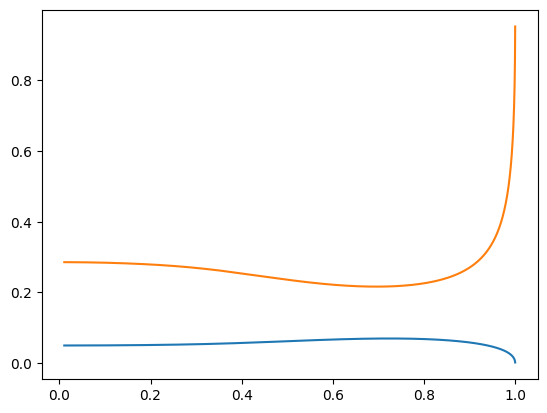

In [720]:
plt.plot(np.cos(x), cc, marker='')
plt.plot(np.cos(x), hh/cc, marker='')
#plt.yscale('log')

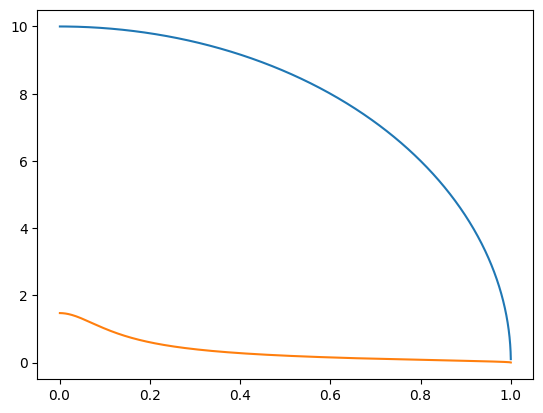

In [598]:
t = 0.
plos1 = [R * (np.sin(x) + np.sin(t)) for x in np.linspace(0.01,1.57,1000)]
plos2 = [quad(pathlength_los, t, x, args=(R, x, R0))[0] for x in np.linspace(0.01,1.57,1000)]
xr = np.linspace(0.01,1.57,1000)
plt.plot(np.cos(xr), plos1)
plt.plot(np.cos(xr), plos2)

/var/folders/73/5cpbpjm96nn4n2mcc500_zbh0000gn/T/ipykernel_6277/4265588272.py:64: RuntimeWarning: invalid value encountered in divide
  ratio = I_ice / I_cont


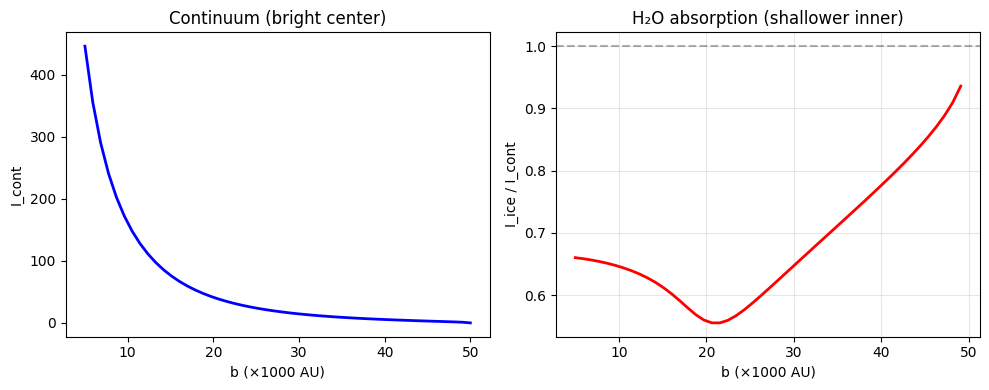

In [1228]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

R_cloud = 0.05
R0      = 0.02
tau_cont0 = 2e-3 * 1e3
tau_ice0  = 50e-3 * 1e3

# Ice depletion parameters
r_warm = 0.02  # pc, inner warm region
width  = 0.003  # pc, transition width

def rho(r, R0=R0):
    return R0**2 / (r**2 + R0**2)

def ice_factor(r):
    """Ice abundance: depleted inside r_warm, full outside."""
    return 0.5 * (1 + np.tanh((r - r_warm)/width))

def tau_radial(r, tau_cont):
    if r <= 0:
        return 0.0
    return tau_cont * quad(lambda rp: rho(rp), 0, r)[0]

def tau_los(b, s, tau_cont, tau_ice):
    s_max = np.sqrt(max(R_cloud**2 - b**2, 0))
    if s >= s_max:
        return 0.0
    def integrand(sp):
        r = np.sqrt(b**2 + sp**2)
        return rho(r) * (tau_cont + tau_ice * ice_factor(r))  # ← ice gradient
    return quad(integrand, s, s_max)[0]

def emissivity(r, tau_cont):
    if r == 0:
        return 0.0
    J_r = np.exp(-tau_radial(r, tau_cont)) / r**2
    return rho(r) * J_r

def intensity_continuum(b):
    if b >= R_cloud:
        return 0.0
    s_max = np.sqrt(R_cloud**2 - b**2)
    def integrand(s):
        j = emissivity(np.sqrt(b**2 + s**2), tau_cont0)
        tau_l = tau_los(b, s, tau_cont0, 0)
        return j * np.exp(-tau_l)
    return quad(integrand, -s_max, s_max)[0]

def intensity_ice(b):
    if b >= R_cloud:
        return 0.0
    s_max = np.sqrt(R_cloud**2 - b**2)
    def integrand(s):
        j = emissivity(np.sqrt(b**2 + s**2), tau_cont0)
        tau_l = tau_los(b, s, tau_cont0, tau_ice0)
        return j * np.exp(-tau_l)
    return quad(integrand, -s_max, s_max)[0]

b_vals = np.linspace(0.005, R_cloud, 50)
I_cont = np.array([intensity_continuum(b) for b in b_vals])
I_ice  = np.array([intensity_ice(b)     for b in b_vals])
ratio = I_ice / I_cont

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,4))
ax1.plot(b_vals*1000, I_cont, 'b-', lw=2)
ax1.set_xlabel("b (×1000 AU)")
ax1.set_ylabel("I_cont")
ax1.set_title("Continuum (bright center)")

ax2.plot(b_vals*1000, ratio, 'r-', lw=2)
ax2.axhline(1.0, color='k', ls='--', alpha=0.3)
ax2.set_xlabel("b (×1000 AU)")
ax2.set_ylabel("I_ice / I_cont")
ax2.set_title("H₂O absorption (shallower inner)")
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


/var/folders/73/5cpbpjm96nn4n2mcc500_zbh0000gn/T/ipykernel_49826/3180857611.py:64: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  tau_in[i] = np.trapz(rhoeff, s_use[:i+1]) * kappa_ext
/var/folders/73/5cpbpjm96nn4n2mcc500_zbh0000gn/T/ipykernel_49826/3180857611.py:73: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  tau_out[i] = np.trapz(rhoeff, s_use[i:]) * kappa_ext
/var/folders/73/5cpbpjm96nn4n2mcc500_zbh0000gn/T/ipykernel_49826/3180857611.py:84: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  I.append(np.trapz(contrib, s_use))


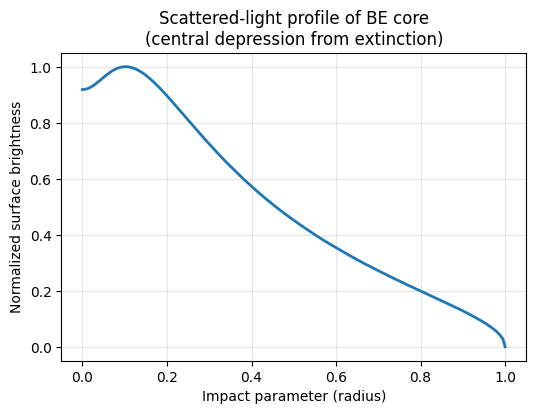

In [138]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Grid and geometry
# -----------------------------
R_max = 1.0          # core radius (arbitrary units)
nr = 500
ns = 800

r = np.linspace(0, R_max, nr)
b_vals = np.linspace(0, R_max, 200)

# Line-of-sight coordinate
s = np.linspace(-R_max, R_max, ns)

# -----------------------------
# Bonnor–Ebert–like density profile
# (analytic approximation)
# -----------------------------
rho0 = 1.0
r0 = 0.1             # flat inner radius
rho = rho0 / (1 + (r / r0)**2)
rhosat = rho0 * 1e6

# Interpolation helper
def rho_interp(x):
    return np.interp(x, r, rho, left=0, right=0)

# -----------------------------
# Dust properties
# -----------------------------
kappa_abs = 2      # absorption opacity
kappa_sca = 3      # scattering opacity
kappa_ext = kappa_abs + kappa_sca
albedo = kappa_sca / kappa_ext

# -----------------------------
# Optical depth integrals
# -----------------------------
def tau_along_path(r_vals):
    """Cumulative optical depth along LOS"""
    return np.cumsum(rho_interp(r_vals)) * kappa_ext * (2 * R_max / ns)

# -----------------------------
# Surface brightness
# -----------------------------
I = []

for b in b_vals:
    r_los = np.sqrt(b**2 + s**2)
    inside = r_los <= R_max

    r_use = r_los[inside]
    s_use = s[inside]

    # Optical depth from surface -> scattering point
    tau_in = np.zeros_like(r_use)
    for i in range(len(r_use)):
        path = np.sqrt(b**2 + s_use[:i+1]**2)
        rhor = rho_interp(path)
        #tau_in[i] = np.trapz(rhor, s_use[:i+1]) * kappa_ext
        rhoeff = rhor * ((1-albedo) / (1+rhor/rhosat) + albedo)
        tau_in[i] = np.trapz(rhoeff, s_use[:i+1]) * kappa_ext

    # Optical depth from scattering point -> observer
    tau_out = np.zeros_like(r_use)
    for i in range(len(r_use)):
        path = np.sqrt(b**2 + s_use[i:]**2)
        rhor = rho_interp(path)
        #tau_out[i] = np.trapz(rhor, s_use[i:]) * kappa_ext
        rhoeff = rhor * ((1-albedo) / (1+rhor/rhosat) + albedo)
        tau_out[i] = np.trapz(rhoeff, s_use[i:]) * kappa_ext

    # Incident radiation field
    J_inc = np.exp(-tau_in)

    # Scattered emissivity
    emissivity = rho_interp(r_use) * kappa_sca * J_inc

    # Attenuation after scattering
    contrib = emissivity * np.exp(-tau_out)

    I.append(np.trapz(contrib, s_use))

I = np.array(I)
I_cont = I.copy()

# Normalize
I /= I.max()

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(6,4))
plt.plot(b_vals, I, lw=2)
plt.xlabel("Impact parameter (radius)")
plt.ylabel("Normalized surface brightness")
plt.title("Scattered-light profile of BE core\n(central depression from extinction)")
plt.grid(alpha=0.3)
plt.show()


/var/folders/73/5cpbpjm96nn4n2mcc500_zbh0000gn/T/ipykernel_49826/1851352628.py:2: RuntimeWarning: invalid value encountered in divide
  plt.plot(b_vals, I_ice/I_cont, lw=2)
/var/folders/73/5cpbpjm96nn4n2mcc500_zbh0000gn/T/ipykernel_49826/1851352628.py:3: RuntimeWarning: invalid value encountered in divide
  plt.plot(b_vals, I_ice2/I_cont, lw=2)


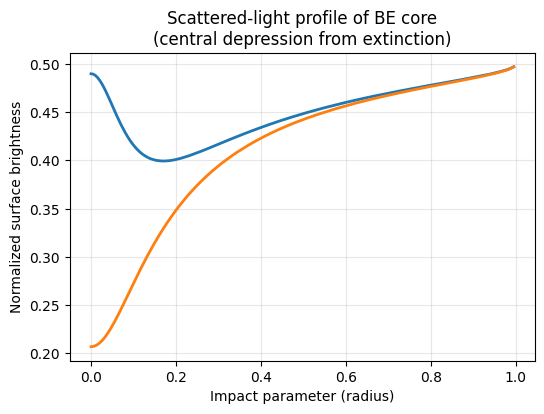

In [139]:
plt.figure(figsize=(6,4))
plt.plot(b_vals, I_ice/I_cont, lw=2)
plt.plot(b_vals, I_ice2/I_cont, lw=2)
plt.xlabel("Impact parameter (radius)")
plt.ylabel("Normalized surface brightness")
plt.title("Scattered-light profile of BE core\n(central depression from extinction)")
plt.grid(alpha=0.3)
plt.show()


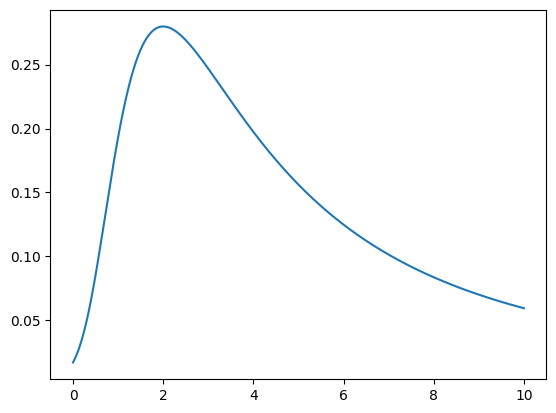

In [624]:
ptot = quad(pathlength_central, 0, R, args=(R0,))[0]
pcen = np.array([quad(pathlength_central, 0, r, args=(R0,))[0] for r in np.linspace(0,R,1000)])

R, R0, tau_h2o, tau_cont, ext_fact = 10, 1, 50, 4, 6
rho_R = np.array([R0**2 / (r**2 + R0**2) for r in np.linspace(0,R,1000)])
lum_R = np.exp(-tau_cont*pcen) / r**2 + ext_fact * np.exp(-tau_cont * (ptot-pcen))

plt.plot(np.linspace(0,R,1000), lum_R*rho_R)

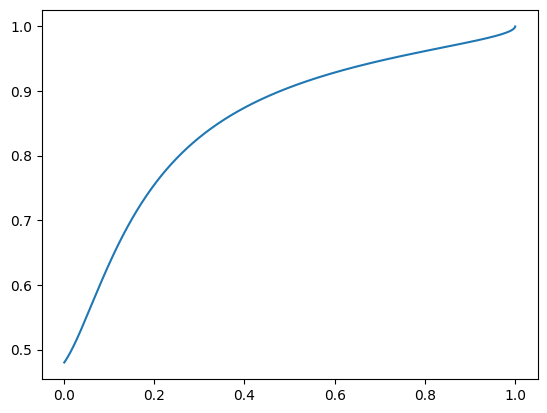

In [602]:
plt.plot(np.cos(x), hh/cc, marker='')
#plt.yscale('log')

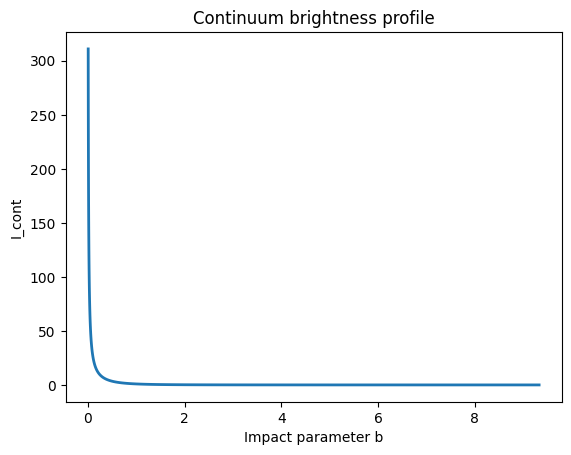

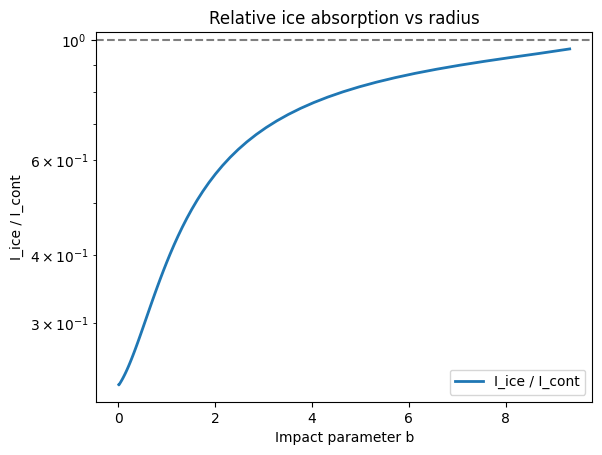

In [542]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

# Global parameters (you can tune these)
R   = 10.0   # outer radius (arbitrary units)
R0  = 1.0    # density scale radius
r_evap = R0/100.0
width  = R0/1000.0

# ------------------------------
# Basic radial profiles
# ------------------------------

def rho(r, R0=R0):
    """Spherical density profile rho(r) = R0^2 / (r^2 + R0^2)."""
    return R0**2 / (r**2 + R0**2)

def ice_factor(r):
    """0 inside r_evap, ~1 outside, smoothed with tanh."""
    return 0.5 * (1.0 + np.tanh((r - r_evap)/width))

# ------------------------------
# Optical depths
# ------------------------------

def tau_radial(r, tau_cont):
    """
    Radial continuum optical depth from center to radius r.
    tau_cont is an overall scaling factor (per unit 'rho' * dr).
    """
    if r <= 0:
        return 0.0
    integrand = lambda rp: rho(rp)
    tau = tau_cont * quad(integrand, 0.0, r, epsabs=1e-5, epsrel=1e-4)[0]
    return tau

def tau_los(b, s, tau_cont, tau_h2o):
    """
    LOS optical depth from position (b,s) to the near side (s -> +sqrt(R^2 - b^2)).
    b: impact parameter, s: current LOS position (negative behind, positive front).
    """
    s_max = np.sqrt(max(R**2 - b**2, 0.0))
    if s >= s_max:
        return 0.0

    def integrand(sp):
        r = np.sqrt(b**2 + sp**2)
        return rho(r) * (tau_cont + tau_h2o * ice_factor(r))

    tau = quad(integrand, s, s_max, epsabs=1e-5, epsrel=1e-4)[0]
    return tau

# ------------------------------
# Local emissivity from central source
# ------------------------------

def emissivity(r, tau_cont):
    """
    Local emissivity j(r) ∝ rho(r) * J(r),
    where J(r) ∝ exp(-tau_radial) / r^2 is the attenuated central intensity.
    """
    if r == 0:
        return 0.0
    J_r = np.exp(-tau_radial(r, tau_cont)) / r**2
    return rho(r) * J_r

# ------------------------------
# Specific intensity at impact parameter b
# ------------------------------

def intensity(b, tau_h2o, tau_cont):
    """
    Compute I(b) by integrating along the line of sight through the envelope.
    b: impact parameter (0 = center, up to R).
    """
    if b >= R:
        return 0.0

    # s ranges from -s_max (far side) to +s_max (near side)
    s_max = np.sqrt(R**2 - b**2)

    def integrand(s):
        r = np.sqrt(b**2 + s**2)
        j_r = emissivity(r, tau_cont)
        # attenuation from this point to the observer
        tau_l = tau_los(b, s, tau_cont, tau_h2o)
        return j_r * np.exp(-tau_l)

    I, _ = quad(integrand, -s_max, s_max, epsabs=1e-5, epsrel=1e-4)
    return I

# ------------------------------
# Convenience wrappers for continuum vs ice
# ------------------------------

def continuum_intensity(b):
    # very small continuum opacity to keep envelope optically thin-ish
    return intensity(b, tau_h2o=0.0, tau_cont=1e-4)

def ice_intensity(b):
    return intensity(b, tau_h2o=1.0, tau_cont=1e-4)

# ------------------------------
# Example: center-to-edge profile
# ------------------------------

# impact parameter grid from center (0) to edge (R)
b_vals = np.logspace(-2, np.log10(R), 100)

I_cont = np.array([continuum_intensity(b) for b in b_vals])
I_ice  = np.array([ice_intensity(b) for b in b_vals])

# avoid division by zero; restrict to inside envelope
mask = I_cont > 0
b_plot  = b_vals[mask]
ratio   = I_ice[mask] / I_cont[mask]

plt.figure()
plt.plot(b_plot, I_cont[mask], label="Continuum", lw=2)
plt.xlabel("Impact parameter b")
plt.ylabel("I_cont")
plt.title("Continuum brightness profile")

plt.figure()
plt.plot(b_plot, ratio, label="I_ice / I_cont", lw=2)
plt.xlabel("Impact parameter b")
plt.ylabel("I_ice / I_cont")
plt.yscale('log')
plt.title("Relative ice absorption vs radius")
plt.axhline(1.0, color='k', ls='--', alpha=0.5)
plt.legend()
plt.show()
